# Clean corpus: the *ṭawīl*

This notebook runs `clean_ashaar.py` (in this folder) and looks quickly at the
*ṭawīl* verses of the cleaned corpus. Variants such as مجزوء الطويل are left
out. Unit: **verses**.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from clean_ashaar import clean, filter_bahr

plt.rcParams["font.family"] = "DejaVu Sans"
corpus = clean()
tawil = filter_bahr(corpus, "طويل")
print(f"Cleaned corpus: {len(corpus):,} verses, of which {len(tawil):,} ṭawīl verses")

Cleaned corpus: 265,609 verses, of which 72,654 ṭawīl verses


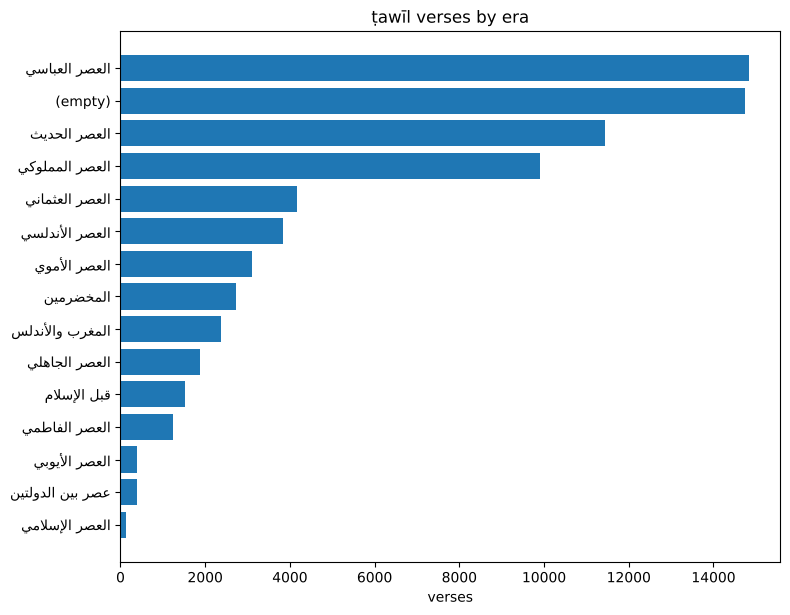

In [2]:
def barh(series, title):
    fig, ax = plt.subplots(figsize=(8, 0.35 * len(series) + 1))
    ax.barh(series.index.astype(str)[::-1], series.values[::-1])
    ax.set_title(title)
    ax.set_xlabel("verses")
    fig.tight_layout()
    plt.show()

barh(tawil["era"].fillna("(empty)").value_counts(), "ṭawīl verses by era")

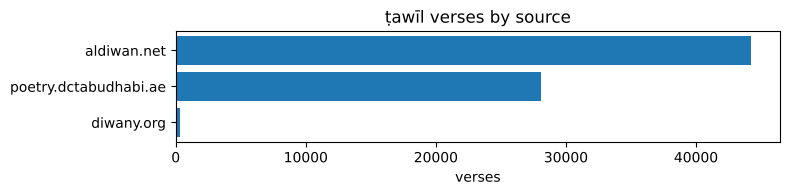

In [3]:
barh(tawil["source"].value_counts(), "ṭawīl verses by source")

In [4]:
for _, verse in tawil.sample(5, random_state=0).iterrows():
    print(f"({verse['poet']}, {verse['era']}, ratio {verse['adjusted_ratio']:.2f})")
    print(f"   {verse['sadr']}  #  {verse['ajuz']}")

(محمد الشوكاني, العصر الحديث, ratio 0.93)
   وقُولِي لَهُ إنّا نَزَلْنا جِوارَهُ  #  ولِلْجارِ حَقُّ الضَّيْفِ مِنْ كُلِّ سابِقِ
(أبو زيد الفازازي, nan, ratio 0.81)
   رَمَانِي بسَهمٍ مِن سِهامِ صُدُودِهِ  #  ولاَ هَدَفٌ إلاَّ التَّرائِبُ والنَّحرُ
(فتيان الشاغوري, nan, ratio 0.83)
   أَبى الحُبُّ إِلّا أَنَّني بَعدَ عِزَّةٍ  #  ذَليلٌ لِمَن بِالحُبِّ يَستَعبِدُ الحَرّا
(ابن حيوس, العصر الأندلسي, ratio 0.80)
   وَمَن أَبوهُ عَلِيٌّ لا يُنازِعُهُ  #  ميراثَ أَحمَدَ باغٍ عَمُّهُ قُثَمُ
(جبيهاء الأشجعي, nan, ratio 0.82)
   رَعَت عُشُبَ الجَولانِ ثُمَّ تَصَيَّفَت  #  وَضيعَةَ جَلسِ فَهيَ بَدّاءُ راجِحُ


**Observed.** The cleaned corpus holds 265,609 verses, of which 72,654
*ṭawīl* verses. The largest eras are العصر العباسي (14,829 verses) and
العصر الحديث (11,428); 14,744 *ṭawīl* verses have no era.